In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
def f(x):
  return 3*x**2 - 4*x + 5

In [5]:
f(3.0)

20.0

In [6]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

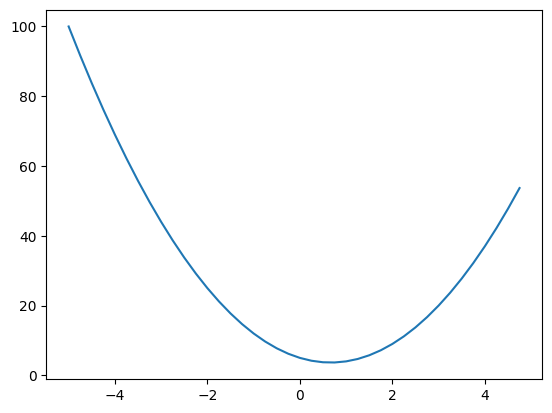

In [7]:
plt.plot(xs,ys)

In [8]:
#This is the basis of the derivative and here we are learning about the basics of the derivation of a function
h = 0.00000001
x = 3.0
(f(x + h) - f(x))/h

14.00000009255109

In [9]:
#For the case of x = 2/3, the value of the derivative of the function is 0.
h = 0.00000001
x = 2/3
(f(x + h) - f(x))/h

0.0

In [10]:
#Example - 1, For the more COMPLEX CASES
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

4.0


In [11]:
h = 0.00001

a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
a += h
d2 = a*b + c
print('d1', d1)
print('d2', d2) #Since a negative number -3 is being multiplied with 'a', hence the overall value of d2 is less than d1.
#As being metioned above the slope of the function wrt a is negative.
print("Solpe is: ", (d2-d1)/h)

d1 4.0
d2 3.9999699999999994
Solpe is:  -3.000000000064062


In [12]:
#Let us find the derivative wrt b
h = 0.00001

a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
b += h
d2 = a*b + c
print('d1', d1)
print('d2', d2) #Since a negative number positve is being added into a negative, hence the value of the negative reduces, making the slope positive.
#As being metioned above the slope of the function wrt b is positive.
print("Solpe is: ", (d2-d1)/h)

d1 4.0
d2 4.00002
Solpe is:  2.0000000000131024


In [13]:
#Let us find the derivative wrt c
h = 0.00001

a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
c += h
d2 = a*b + c
print('d1', d1)
print('d2', d2)
#The slope is: -
print("Solpe is: ", (d2-d1)/h)

d1 4.0
d2 4.00001
Solpe is:  0.9999999999621422


In [14]:
#As we were doing the things above in a more specific manner and with the help of variables, will make a class here for the whole bunch of variables.
class Value:

  def __init__(self, data, _children=(), _op=(), label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None #This is doing nothing here: - ??
    self._prev = set(_children) #Here, children(), is one of the tuple that is having the information of previously operated values.
    self._op = _op #Here, op() is the tuple having the information regarding the operator that is being used for the operation of the values.
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})" #The syntax = This is printing the "Value(data={Here it is going to print the data of the variable})"

  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')

    def _backward():
      #This is the grad cal for the addition, as value of the self grad is 1 * grad of the further node.
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward

    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')

    def _backward():
      #This is the grad cal for the multiplication, and uses the similar concept as it is being mentioned below: -
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward

    return out

  #The power function

  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')

    def _backward():
      self.grad += (other * self.data**(other-1)) * out.grad
    out._backward = _backward

    return out

  #The use of the __rmul__ is that since python does the multiplication in the form of mentioned here: -
  #If a * 2 ----> a.data __mul__ (2).
  #But the opposite is not possible as 2 * a ---> 2.data --> This is not possible.
  #Hence, the use of __rmul__ makes the things possible.
  def __rmul__(self, other):
    return self * other

  #The division part:)

  def __truediv__(self, other): #self/other
    return self * other**-1

  def __neg__(self): #-self
    return self * -1

  def __sub__(self, other): #self - other
    return self + (-other)

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')

    def _backward():
      self.grad += (1 - t**2) * out.grad
      #The value of out.grad for each of the case is 0.0 and need to be modified before the changes.
    out._backward = _backward

    return out


  #This is the exp function and the backward() for the same.
  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')

    def _backward():
      self.grad += out.data * out.grad
    out._backward = _backward

    return out

#Here, I am defining the topological sort, with the help of the same can run the backpropogation in the loop, automating the things: -
  def backward(self):
    topo = []
    visited = set()
    def build_topo (v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed (topo):
      node._backward()

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f') #What is the reason for the mentioning of -2 here?
L = d * f; L.label = 'L'
L

Value(data=-8.0)

In [15]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [16]:
d._op #Here, '+' iss coming, since the last operator was a plus, for the addition of a*b "+"" c.

'+'

In [17]:
a+b

Value(data=-1.0)

In [18]:
a*b + c

Value(data=4.0)

In [19]:
#For the case of visulization of the backpropagation and derivative (grad), this is a set of code for the making of the grapgh, does not have relation with the learning.
from graphviz import Digraph

# 'graphviz' this is one of the free source for the making of the graph, this has been used for the making of the graph: -

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

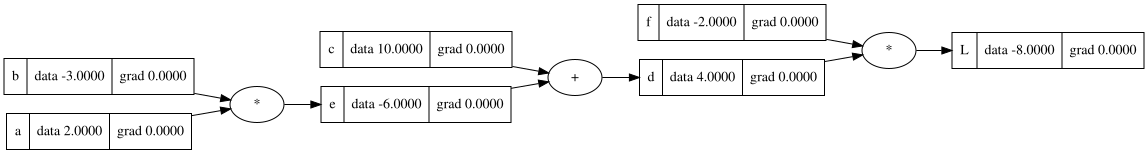

In [20]:
draw_dot(L)

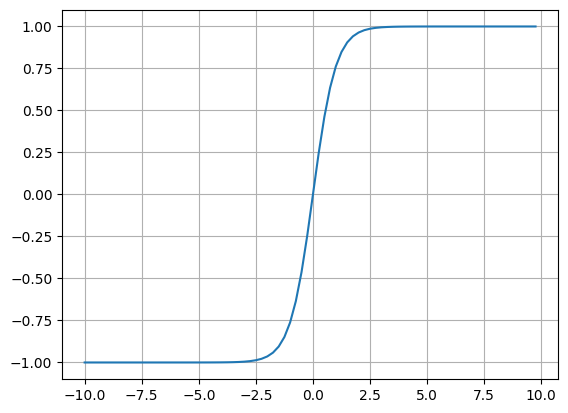

In [21]:
#Here, this is the plot for the ACTIVATION FUNCTION - tanhx()
plt.plot(np.arange(-10, 10, 0.25), np.tanh(np.arange(-10, 10, 0.25)));
plt.grid();

In [22]:
#EXAMPLE - 2 - MANUAL BACKPROPOGATION
# inputs x1,x2
#Here, providing the inputs x1 and x2

x1 = Value (2.0, label='x1')
x2= Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

# x1w1 + x2w2 + b
#Here, each value is being multiplied with a weight (Multiplying input values by weights in a neural network determines the importance and strength of each signal).
#Then a bias is added into the sum(product).

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
o.backward()

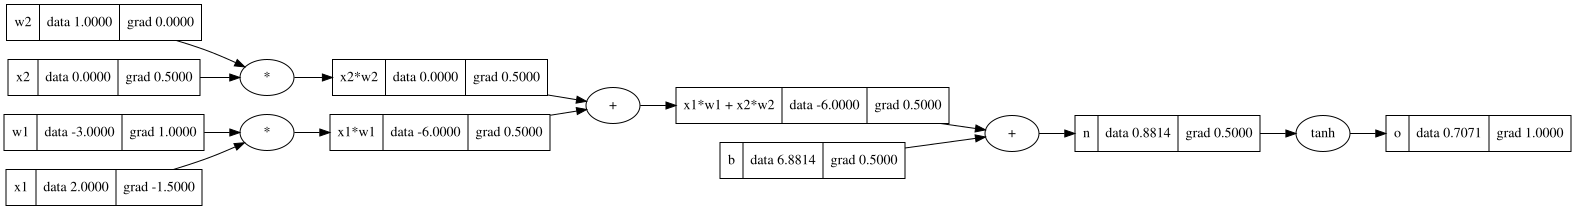

In [23]:
draw_dot(o)

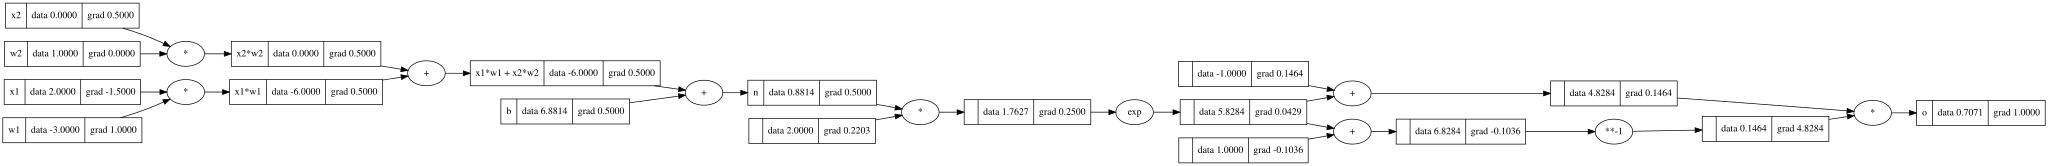

In [24]:
#EXAMPLE - 2 - MANUAL BACKPROPOGATION
# inputs x1,x2
#Here, providing the inputs x1 and x2

x1 = Value (2.0, label='x1')
x2= Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

# x1w1 + x2w2 + b
#Here, each value is being multiplied with a weight (Multiplying input values by weights in a neural network determines the importance and strength of each signal).
#Then a bias is added into the sum(product).

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
#-----------
e = (2*n).exp()
o = (e - 1) / (e + 1)
#-----------
o.label = 'o'
o.backward()
draw_dot(o)

#As it has been expected the forward and the backward passes worked in perfectly okay manner. The number of noded got increased as the number of calculation for the same got increased.

In [25]:
o.backward()

In [26]:
#This is once again we did the backpropogation via the help of the backward() function, not doing the calculation manually - :)
o.grad = 1.0

In [27]:
o._backward()

In [28]:
n._backward()

In [29]:
x1w1x2w2._backward()

In [30]:
x1w1._backward()
x2w2._backward()

In [31]:
#Here for the case of the first two nodes of multiplication, we have to use the same method as it is being used in the previous case, for the finding of the grad.
#w1.grad = x1w1.grad * x1.data
#x1.grad = x1w1.grad * w1.data
#The similar step is used for the other portion also.
w1.grad = 1.0
x1.grad = -1.5
w2.grad = 0.0
x2.grad = 0.5

In [32]:
x1w1.grad = 0.5
x2w2.grad = 0.5

In [33]:
x1w1x2w2.grad = 0.5
b.grad = 0.5

In [34]:
n.grad = 0.5

In [35]:
o.grad = 1.0

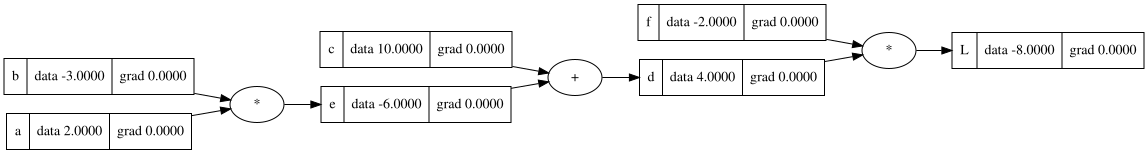

In [36]:
# a.data += 0.01 * a.grad
# b.data += 0.01 * b.grad
# c.data += 0.01 * c.grad
# f.data += 0.01 * f.grad

# #Here, we are giving a positive change to all the data values of the variable hence, expecting a positive change in the value of L -> I should become less negative.

# e = a*b; e.label = 'e'
# d = e + c; d.label = 'd'
# L = d * f; L.label = 'L'
# print(L.data)
draw_dot(L)

In [37]:
a.grad = 6.0
b.grad = -4.0

In [38]:
c.grad = -2.0
e.grad = -2.0

In [39]:
L.grad = 1

In [40]:
f.grad = 4.0
d.grad = -2.0

In [41]:
#This is one of the function that is created for finding of the derivative of the L wrt to any of the variables. Just change the value of the variable by h -> 0.

#Here, we did the derivation of L wrt c and e, this is one of the most imp step for the backpropogation, in the same we have used the main concept of the chain rule.
#dL/de = dL/dd*dd/de -> This is coming from the chain rule.
#As L = d*f and d is a fuction of 'e'.
#dL/de = (-2.0) * (d(e+c)/de = 1)
#dL/de = -2.0

def lol():

  h = 0.001

  a = Value(2.0, label='a')
  b = Value(-3.0, label='b')
  c = Value(10.0, label='c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label='f') #What is the reason for the mentioning of -2 here?
  L = d * f; L.label = 'L'
  L1 = L.data

  a = Value(2.0, label='a')
  b = Value(-3.0 + h, label='b')
  c = Value(10.0, label='c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label='f') #What is the reason for the mentioning of -2 here?
  L = d * f; L.label = 'L'
  L2 = L.data

  print((L2-L1)/h)

lol()

-3.9999999999995595


**DAY - 2 - AUTOGRAD (AI/ML)**


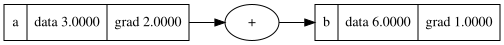

In [42]:
a = Value(3.0, label='a')
b = a + a ; b.label = 'b'
b.backward()
draw_dot(b)

#Here, as it is coming in the output, the grad of b wrt a should be 2, but it is coming 1, because of one of the bug into the 'backgrad()' function, that is keeping the value of the grad initially 1 for every individual in the operation, but here both are same.
#Example - a + a
#Grad -> db/da = 1 --> i.
#Grad -> db/da = 1 --> ii.
#Hence, it is coming as 1.


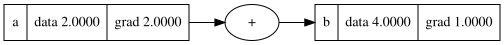

In [43]:
a = Value(2.0, label='a')
b = a + a ; b.label = 'b'
b.backward()
draw_dot(b)

#Here I used += for the accumulation of all the gradients, we are basically adding all the gradients that are for the same variable.

In [44]:
a = Value(2.0)
a+1

Value(data=3.0)

In [45]:
a = Value(2.0)
a * 2
2 * a

Value(data=4.0)

In [46]:
a = Value(2.0)
b = Value(4.0)
a/b

Value(data=0.5)

In [47]:
a = Value(2.0)
b = Value(4.0)
a - b

Value(data=-2.0)

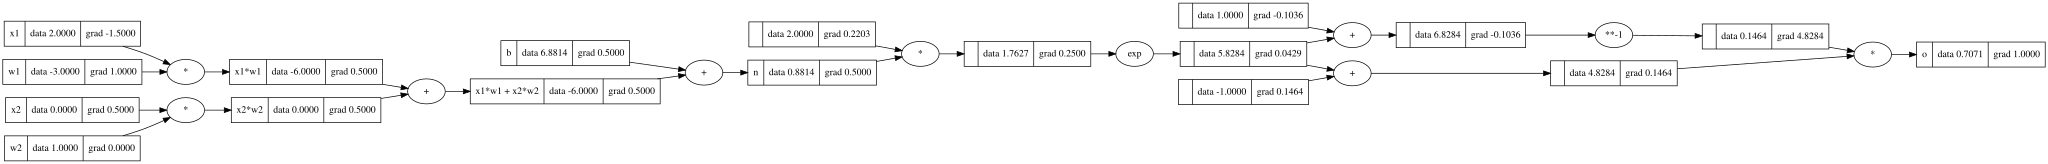

In [48]:
#EXAMPLE - 2 - MANUAL BACKPROPOGATION
# inputs x1,x2
#Here, providing the inputs x1 and x2

x1 = Value (2.0, label='x1')
x2= Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

# x1w1 + x2w2 + b
#Here, each value is being multiplied with a weight (Multiplying input values by weights in a neural network determines the importance and strength of each signal).
#Then a bias is added into the sum(product).

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
#-----------
e = (2*n).exp()
o = (e - 1) / (e + 1)
#-----------
o.label = 'o'
o.backward()
draw_dot(o)

#As it has been expected the forward and the backward passes worked in perfectly okay manner. The number of noded got increased as the number of calculation for the same got increased.

In [49]:
import torch

In [50]:
#Since, all the mentioned here are the leaf nodes, so python considers them as they don't need the gradients so it is mentioned expicitly here that they need grads.

x1 = torch.Tensor([2.0]).double() ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double() ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double() ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double() ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double() ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('___')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())
#Here, we are getting the grad of all the values mentioned earlier with the help of 'pytorch'
#Here o.data.item and o.item shows the same result.

0.7071066904050358
___
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [51]:
torch.tensor([[1,2,3], [4,5,6]])

tensor([[1, 2, 3],
        [4, 5, 6]])

In [52]:
torch.tensor([2.0]).double().dtype

torch.float64

In [53]:
#.grad is a tensor and .grad.item() is the individual value of the same
x1.grad

tensor([-1.5000], dtype=torch.float64)

In [54]:
x1.grad.item()

-1.5000003851533106

*Here, we are going to make one Neural Network that also subscribes the pyTorch, and also tells how pyTorch deisgns its Neural Network Models.*

---



In [96]:
import random

class Neuron:

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] #This is the weight that is being multiplied with the value 'x', the weight is being generated as any of the random number between -1 to +1.
        self.b = Value(random.uniform(-1,1)) #This is the bias that is being added to the product of 'x' and the weight, the bias is being generated as any of the random number between -1 to +1.

    def __call__(self, x):
        # w * x + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), Value(0.0)) + self.b # This is the real activation that is the summation of all the calculations.
        #Here, the Value(0.0), is the start, this is basically for the efficency of the system.
        out = act.tanh() #Passed obver the activation function
        return out

    def parameters(self):
      return self.w + [self.b]

class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
      return [p for neuron in self.neurons for p in neuron.parameters()]
      params = []
      for neuron in self.neurons:
        ps = neuron.parameters()
        params.extend(ps)
      return params

class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
      return [p for layer in self.layers for p in layer.parameters()]

x = [2.0, 3.0]
n = Neuron(2) #The value of x is '2'.
n(x)

#Everytime, different result as the value is being choosen randomly.

Value(data=-0.03871987777473213)

In [98]:
x = [2.0, 3.0]
n = Layer(2, 3) #Here, nin(the first = 2), this states the number of inputs, and the nout(the second = 3), states the no. of outputs.
n(x)

[Value(data=0.7591690753207917),
 Value(data=0.9442838101606502),
 Value(data=0.8346055215800826)]

In [99]:
#EXAMPLE - 1 (MLP)
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=0.2977084080658936)

In [103]:
len(n.parameters())
#These are the number of parameters:)

41

In [104]:
n.parameters()
#These are all the parameters

[Value(data=0.7384714433443391),
 Value(data=-0.5243083222103286),
 Value(data=0.3345938634481076),
 Value(data=-0.5283235220478939),
 Value(data=-0.7268081184434794),
 Value(data=0.5679252583488774),
 Value(data=-0.8640316917055597),
 Value(data=-0.7773943889166117),
 Value(data=0.2522785160654193),
 Value(data=0.2339739226983073),
 Value(data=0.9251755670050894),
 Value(data=-0.30809706849609486),
 Value(data=0.18599616587037948),
 Value(data=-0.4530989603310034),
 Value(data=-0.5291484393848616),
 Value(data=0.45468242416833227),
 Value(data=0.36493369285898125),
 Value(data=0.6826027572782023),
 Value(data=-0.4741303784214861),
 Value(data=-0.9155889265466088),
 Value(data=0.01711521192502552),
 Value(data=-0.3944900519389116),
 Value(data=-0.09278427694516278),
 Value(data=0.24433519322022357),
 Value(data=0.8113823658239101),
 Value(data=-0.6986984329478265),
 Value(data=-0.47170087365554014),
 Value(data=-0.21469932531950509),
 Value(data=0.6565827214321376),
 Value(data=0.30563

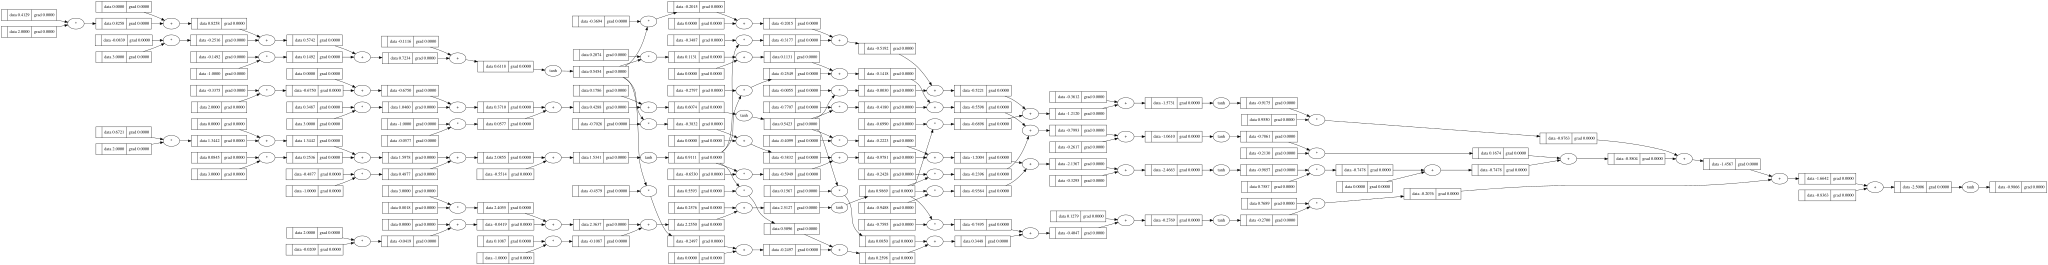

In [58]:
draw_dot(n(x))

In [234]:
#EXAMPLE - 2
#This is one of the datasets
#Here, we are giving the value of x and the exppected value of y, this is the binary classifier

n = MLP(3, [4, 4, 1])

xs = [
[2.0, 3.0, -1.0],
[3.0, -1.0, 0.5],
[0.5, 1.0, 1.0],
[1.0, 1.0, -1.0],
]
ys = [1.0, - 1.0, - 1.0, 1.0] # desired targets
ypred = [n(x) for x in xs]
ypred

[Value(data=0.636633183328076),
 Value(data=0.6285494149785945),
 Value(data=0.6553285437251889),
 Value(data=0.5950039005590567)]

In [142]:
#Here, we are defining a 'loss', this is one of the parameter for the measurement of the performanace of the MLP: -
#loss = mentioned below
loss = sum(((yout - ygt)**2 for yout, ygt in zip(ypred, ys)), Value(0.0)) #When the pred is exactly equal to the target, the loss = 0
loss

Value(data=4.017719325721232)

In [173]:
ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for yout, ygt in zip(ypred, ys)), Value(0.0)) #When the pred is exactly equal to the target, the loss = 0
loss

Value(data=3.835244596331775)

### 🎯 This is how the MLP make predictions of 1, -1, -1, 1, that we have mentioned as the targets?

Currently, the MLP is making predictions using **untrained random weights**. Here is the step-by-step breakdown of how inputs turn into predictions, and how we change those predictions to eventually match your targets of `[1.0, -1.0, -1.0, 1.0]`:

1. **The Forward Pass:**
   For each input vector (e.g., `[2.0, 3.0, -1.0]`), the numbers flow through the MLP:
   This is the layer that is being defied above: -

   **n = MLP(3,[4, 4, 1])**
   
   * **Layer 1 (3 inputs -> 4 outputs):** Computes 4 weighted sums, passes them through `tanh()`, outputting 4 numbers between -1 and 1.
   * **Layer 2 (4 inputs -> 4 outputs):** Takes those 4 numbers, repeats the process, outputting another 4 numbers.
   * **Layer 3 (4 inputs -> 1 output):** Takes those 4 numbers, processes them, and outputs **one final number** bound between -1 and 1 because of the final `tanh` activation.

2. **The Current Output (Untrained):**
   Because the weights are completely random, your network's current predictions (`ypred`) are:
   * Input 1 $\rightarrow$ Prediction: **`-0.9866`** (Target: `1.0` - *Very wrong!*)
   * Input 2 $\rightarrow$ Prediction: **`-0.9076`** (Target: `-1.0` - *Almost right, but by pure luck!*)
   * Input 3 $\rightarrow$ Prediction: **`-0.9782`** (Target: `-1.0` - *Very close!*)
   * Input 4 $\rightarrow$ Prediction: **`-0.9831`** (Target: `1.0` - *Very wrong!*)

3. **How We Fix This (The Training Loop):**
   To make the predictions match the targets, we must perform **Gradient Descent**:
   * **Calculate Loss:** We measure the error using Squared Error: `(ypred - ytarget)**2`.
   * **Backward Pass:** We call `loss.backward()` to find the gradient (direction of steepest ascent) for every weight and bias.
   * **Update Weights:** We nudge every weight and bias in the *opposite* direction of its gradient (since we want to minimize loss).

In [171]:
loss.backward()
#After running this we are getting the grad for each value 'x', that corresponds to a particular weight 'w'

In [240]:
n.layers[0].neurons[0].w[0].grad
#Here, the grad for this weight is coming positive, hence making the weight of this layer, neuron slightly less, would also have less positive influence on the loss.
#The positive value of 'n.layers[0].neurons[0].w[0].grad', means positive impact of the same on the loss.

24.720760178363935

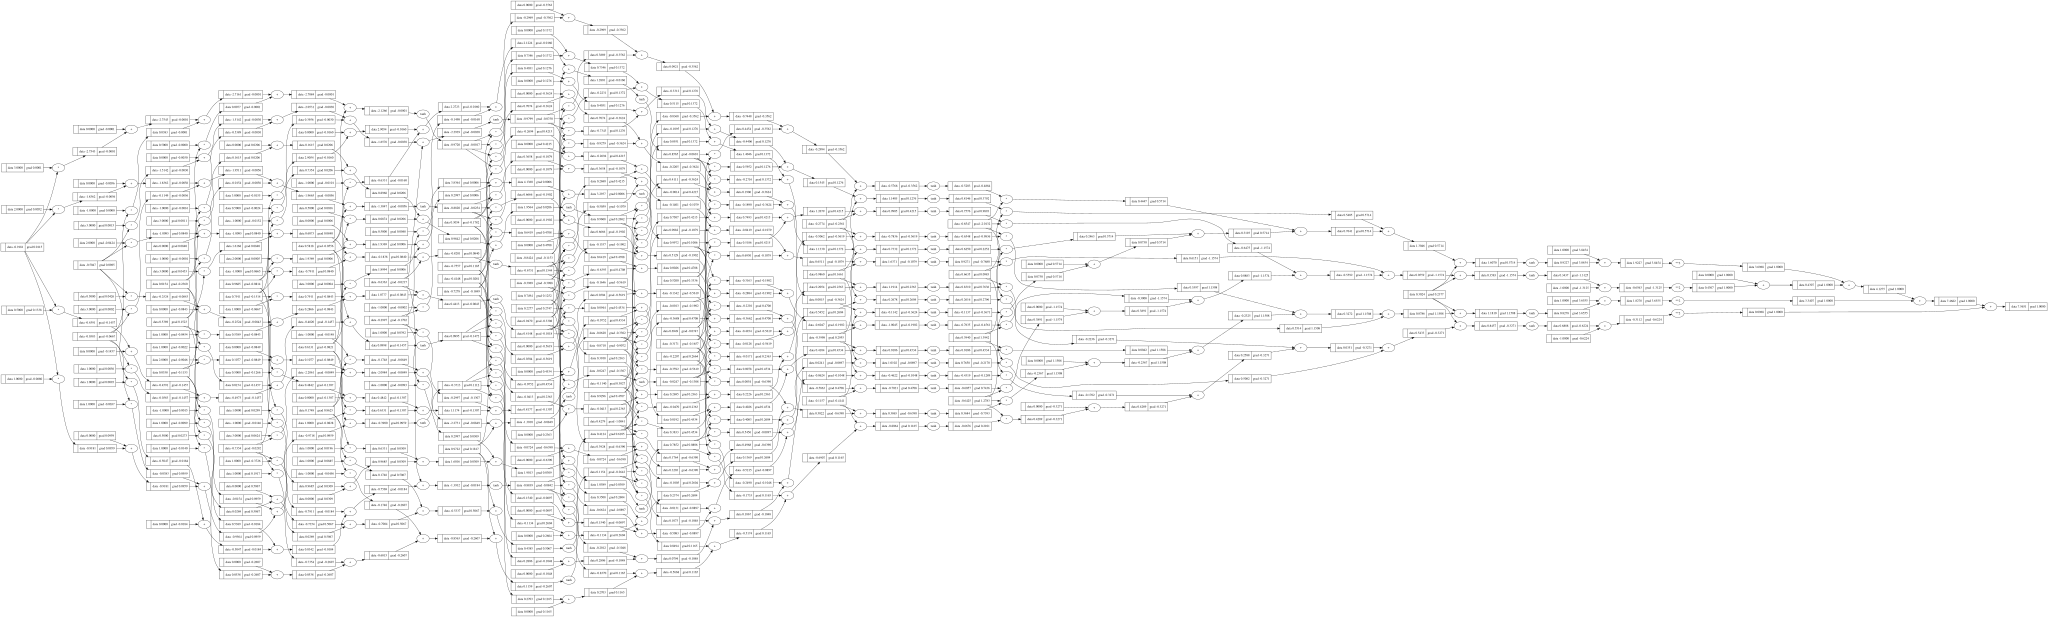

In [111]:
draw_dot(loss)

In [112]:
#In a Multi-Layer Perceptron (MLP) neural network, trainable parameters—consisting of weights and biases—are the core components the model learns and adjusts to map inputs to outputs
#The mentioned below step is for the gradient descent: -

**Gradient descent is an iterative optimization algorithm used to minimize a cost or loss function by adjusting model parameters in the direction of the steepest descent.**

**Here, we are considering the gradient as the vector, which is pointing in the direction of increased loss().**

In [157]:
n.layers[0].neurons[0].w[0].data

-0.9992580801948272

In [172]:
for p in n.parameters():
  p.data += -0.01 * p.grad

In [175]:
n.layers[0].neurons[0].w[0].data

#Since, in our case the value of the grad was positive and we want the new value of the weight of 'n.layers[0].neurons[0].w[0].data', to be slightly less, hence it is lowering the value of loss().
#The seqence is - Forward pass -> backward pass -> change in parameter(Nudge) -> Reduces the value of the loss.

-1.0045183901617372

In [227]:
#This is the step talking about: -
ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for yout, ygt in zip(ypred, ys)), Value(0.0)) #When the pred is exactly equal to the target, the loss = 0
loss

Value(data=0.07372417268490186)

In [228]:
loss.backward()

In [229]:
for p in n.parameters():
  p.data += -0.01 * p.grad

In [225]:
#Each time using the above three, the value of loss is dec.

In [230]:
ypred

[Value(data=0.8464625688839863),
 Value(data=-0.860994971408829),
 Value(data=-0.9564074059471166),
 Value(data=0.8299184968866237)]

In [252]:
#Here, this is the same three step with the help of the for loop : -
for k in range(20):

  #Forward Pass:
  ypred = [n(x) for x in xs]
  loss = sum(((yout - ygt)**2 for yout, ygt in zip(ypred, ys)), Value(0.0))

  #Backward Pass:
  for p in n.parameters():
    p.grad = 0.0 #This is one of the imp line, resolving one of the bug ???
  loss.backward()

  #Update:
  for p in n.parameters():
    p.data += -0.01 * p.grad

  print(k, loss.data)

0 0.0003835364952145422
1 0.0003830859459583805
2 0.00038263630656155587
3 0.0003821875744289559
4 0.0003817397469750346
5 0.0003812928216237749
6 0.00038084679580860505
7 0.00038040166697240807
8 0.0003799574325674369
9 0.0003795140900553095
10 0.00037907163690692794
11 0.00037863007060246037
12 0.00037818938863130354
13 0.00037774958849202045
14 0.0003773106676923226
15 0.0003768726237490153
16 0.0003764354541879528
17 0.0003759991565440071
18 0.00037556372836103667
19 0.00037512916719181614


In [253]:
ypred

[Value(data=0.9866470126817938),
 Value(data=-0.999408313922588),
 Value(data=-0.9999999936533337),
 Value(data=0.9859829816131462)]

In [254]:
#The mentioned above is one of the tiny Neural Network, having the basics of the Neural Networks.